# code_151 · Pinned TimesFM and Chronos against local forecasts

**Book:** section29.2. Restart and run all cells in the pinned environment. Explicit one-time public checkpoint acquisition is required; see the asset guide. Inference then runs offline on CPU with local byte-hash verification. Use the [quickstart](../README.md), [guide](../CHAPTER_29_GUIDE.md), [execution evidence](../CHAPTER_29_EXECUTION.md), [assets](../CHAPTER_29_ASSETS.md) and [registry](../CODE_EXAMPLES.md#code_151). Prerequisites: arrays, forecasting boundaries and Chapters24–26. Allow one minute for execution and30–60minutes to interpret the controls.

All task records are locally generated teaching inputs, not field observations. A generated series or equation family is not evidence of operational validity. Named forecasting checkpoints are identified explicitly; own shared forecasters and learned stencils are not Poseidon, Aurora, TimesFM or Chronos reproductions. Every fit, selected transformation, label budget and final assessment has a declared boundary. CPU float32 neural computations use one thread; numerical references use float64 where appropriate. The literature cutoff is18October2026; access21October2026 does not extend it.


In [1]:
import platform,time,json,copy,hashlib
import numpy as np,scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(3751);torch.use_deterministic_algorithms(True)
START=time.perf_counter();SEED=3751;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 3751


<a id="native-forecasting-backtest"></a>
 ## Execute named checkpoints on a common bounded task
 Forty-eight generated sensor series have hourly sampling, period24, scale/offset differences, drift and autocorrelated noise. The first16series select one of two local tree leaf counts at development origin160;32other series are assessed at origins192/216/240, horizon12and context128. Native TimesFM2.5 and Chronos-BoltTiny receive the same historical values; both use their declared fixed settings, without target weight fitting. Compare a supplied-period seasonal repeat, local ridge autoregression and native histogram boosting trained on historical lagged rows only. Each local fit is reconstructed at its origin. Overlapping origins are retained within a series when summarizing errors;96origins are not96independent sites. Both artifacts are historical checkpoints, not claims of the latest family versions.


Pinned local model files verified; Hub offline mode is enabled.


W1021 13:34:53.596000 53206 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


,model,MAE,median_series_MAE,independent_series,origins_per_series
0,Seasonal repeat,0.189370,0.188332,32,3
1,Local ridge AR,0.154881,0.157004,32,3
2,Lagged histogram,0.196702,0.177596,32,3
3,TimesFM2.5 median,0.168062,0.163051,32,3
4,ChronosBoltTiny median,0.148097,0.157550,32,3


,model,middle80_coverage,mean_width
0,TimesFM2.5,0.803819,0.584283
1,ChronosBoltTiny,0.830729,0.540428


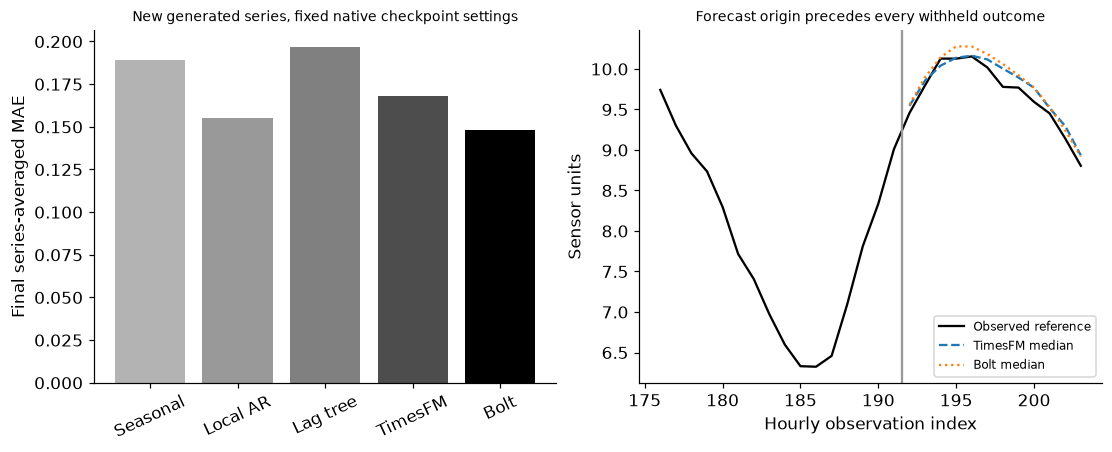

In [2]:
import os
from pathlib import Path
os.environ['HF_HUB_OFFLINE']='1';os.environ['HF_HUB_DISABLE_PROGRESS_BARS']='1'
ASSETS={'timesfm25': {'repository': 'google/timesfm-2.5-200m-pytorch', 'revision': '1d952420fba87f3c6dee4f240de0f1a0fbc790e3', 'files': [{'filename': 'README.md', 'bytes': 2496, 'sha256': '4c3f16633a3d8b9324904bf004429aced2ee009b84e64effb59a902520cc7f2e', 'cache_relative_path': 'build/model-cache/models--google--timesfm-2.5-200m-pytorch/snapshots/1d952420fba87f3c6dee4f240de0f1a0fbc790e3/README.md'}, {'filename': 'config.json', 'bytes': 475, 'sha256': 'cd3315b760d5cc7e278d7afdf41b897031ced888fc6c115bd9b3ac0ea2c47408', 'cache_relative_path': 'build/model-cache/models--google--timesfm-2.5-200m-pytorch/snapshots/1d952420fba87f3c6dee4f240de0f1a0fbc790e3/config.json'}, {'filename': 'model.safetensors', 'bytes': 925181104, 'sha256': '2f776efe6245e42b24bc4153ffdf61810140210e4bd3b01fb21f7aa779ab6ce8', 'cache_relative_path': 'build/model-cache/models--google--timesfm-2.5-200m-pytorch/snapshots/1d952420fba87f3c6dee4f240de0f1a0fbc790e3/model.safetensors'}], 'licence': 'Apache-2.0'}, 'bolt': {'repository': 'amazon/chronos-bolt-tiny', 'revision': 'a0e552de83495b5c28c14c71c374f3e33280b340', 'files': [{'filename': 'README.md', 'bytes': 8659, 'sha256': 'cc7f60bc7290b5e6146589dae9842a3c9b59d254e9d1d65fc2ef127f3c2498cd', 'cache_relative_path': 'build/model-cache/models--amazon--chronos-bolt-tiny/snapshots/a0e552de83495b5c28c14c71c374f3e33280b340/README.md'}, {'filename': 'config.json', 'bytes': 1120, 'sha256': '278f0086733031635fb1c861cb01c1bad6477420c7fcb19381a2993e335785e0', 'cache_relative_path': 'build/model-cache/models--amazon--chronos-bolt-tiny/snapshots/a0e552de83495b5c28c14c71c374f3e33280b340/config.json'}, {'filename': 'model.safetensors', 'bytes': 34622352, 'sha256': '75068728d376d2bec670379eeef4bfb4d24c0cfe24d957451f8d19b447030a32', 'cache_relative_path': 'build/model-cache/models--amazon--chronos-bolt-tiny/snapshots/a0e552de83495b5c28c14c71c374f3e33280b340/model.safetensors'}], 'licence': 'Apache-2.0'}}
MODEL_PATHS={}
ASSET_ROOT=next((root for root in [Path.cwd(),Path.cwd().parent,Path.cwd()/'examples'] if (root/'build/model-cache').is_dir()),Path.cwd().parent)
for name,model in ASSETS.items():
 for file in model['files']:
  path=ASSET_ROOT/file['cache_relative_path']
  if not path.is_file():raise FileNotFoundError('Acquire explicit Chapter29 models first: .venv/bin/python scripts/acquire_chapter29_models.py')
  blob=path.read_bytes();assert len(blob)==file['bytes'] and hashlib.sha256(blob).hexdigest()==file['sha256']
 MODEL_PATHS[name]=path.parent
print('Pinned local model files verified; Hub offline mode is enabled.')

import timesfm,importlib.metadata
from chronos import BaseChronosPipeline
from transformers.utils import logging as transformer_logging
transformer_logging.disable_progress_bar()
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
for package in ['timesfm','chronos-forecasting','transformers','accelerate']:VERSIONS[package]=importlib.metadata.version(package)
tfm=timesfm.TimesFM_2p5_200M_torch.from_pretrained(str(MODEL_PATHS['timesfm25']),local_files_only=True)
tfm.compile(timesfm.ForecastConfig(max_context=128,max_horizon=128,per_core_batch_size=8,normalize_inputs=True,use_continuous_quantile_head=True,force_flip_invariance=False,infer_is_positive=False,fix_quantile_crossing=True))
bolt=BaseChronosPipeline.from_pretrained(str(MODEL_PATHS['bolt']),device_map='cpu',dtype=torch.float32,local_files_only=True)
def digest(network):return hashlib.sha256(b''.join(p.detach().cpu().numpy().tobytes() for p in network.parameters())).hexdigest()
before=[digest(tfm.model),digest(bolt.model)]
series=[]
for j in range(48):
    t=np.arange(264);phase=rng.uniform(0,2*np.pi);amp=rng.uniform(.6,2);level=rng.uniform(5,15);drift=rng.uniform(-.008,.008);noise=rng.normal(0,.12,264)
    for k in range(1,264):noise[k]+=.55*noise[k-1]
    series.append((level+drift*t+amp*np.sin(2*np.pi*t/24+phase)+.2*amp*np.cos(2*np.pi*t/12)+noise).astype(np.float32))
series=np.array(series);H=12
def context(values,origins):return [row[o-128:o].copy() for row in values for o in origins]
def local(values,origins,leaves):
    predictions={'Seasonal repeat':[],'Local ridge AR':[],'Lagged histogram':[]}
    for row in values:
        for origin in origins:
            x=row[origin-128:origin].astype(float);offset=origin-128;features=np.array([np.r_[x[k-24:k],np.sin(2*np.pi*(k+offset)/24),np.cos(2*np.pi*(k+offset)/24)] for k in range(24,128)]);target=x[24:];ar=Ridge(alpha=1).fit(features,target);tree=HistGradientBoostingRegressor(max_leaf_nodes=leaves,max_iter=80,learning_rate=.05,min_samples_leaf=10,l2_regularization=1,early_stopping=False,random_state=SEED).fit(features,target)
            for name,model in [('Local ridge AR',ar),('Lagged histogram',tree)]:
                history=list(x);pred=[]
                for h in range(H):k=origin+h;feature=np.r_[history[-24:],np.sin(2*np.pi*k/24),np.cos(2*np.pi*k/24)];value=float(model.predict(feature[None])[0]);history.append(value);pred.append(value)
                predictions[name].append(pred)
            predictions['Seasonal repeat'].append(x[-24:-24+H])
    return {k:np.array(v) for k,v in predictions.items()}
development=[]
for leaves in [7,15]:
    p=local(series[:16],[160],leaves)['Lagged histogram'];truth=series[:16,160:172];development.append({'leaves':leaves,'MAE':float(np.mean(np.abs(p-truth)))})
selected=min(development,key=lambda r:r['MAE'])['leaves'];origins=[192,216,240];ctx=context(series[16:],origins);truth=np.array([row[o:o+H] for row in series[16:] for o in origins]);point_tfm,q_tfm=tfm.forecast(horizon=H,inputs=ctx)
with torch.no_grad():q_bolt=bolt.predict(torch.tensor(np.array(ctx)),prediction_length=H).numpy()
assert point_tfm.shape==(96,12) and q_tfm.shape==(96,12,10) and q_bolt.shape==(96,9,12)
predictions=local(series[16:],origins,selected);predictions.update({'TimesFM2.5 median':point_tfm,'ChronosBoltTiny median':q_bolt[:,4]});rows=[]
for name,pred in predictions.items():
    per_series=np.abs(pred-truth).reshape(32,3,H).mean((1,2));rows.append({'model':name,'MAE':float(per_series.mean()),'median_series_MAE':float(np.median(per_series)),'independent_series':32,'origins_per_series':3})
bands=[{'model':'TimesFM2.5','middle80_coverage':float(np.mean((truth>=q_tfm[:,:,1])&(truth<=q_tfm[:,:,9]))),'mean_width':float(np.mean(q_tfm[:,:,9]-q_tfm[:,:,1]))},{'model':'ChronosBoltTiny','middle80_coverage':float(np.mean((truth>=q_bolt[:,0])&(truth<=q_bolt[:,8]))),'mean_width':float(np.mean(q_bolt[:,8]-q_bolt[:,0]))}]
assert before==[digest(tfm.model),digest(bolt.model)]
repeated_tfm,_=tfm.forecast(horizon=H,inputs=ctx[:8]);np.testing.assert_allclose(repeated_tfm,point_tfm[:8],atol=1e-6,rtol=0)
RESULTS.update(development_series=16,final_series=32,origins=origins,history=128,horizon=12,tree_candidates=development,selected_tree_leaves=selected,local_tree_rounds=80,local_AR_ridge=1,TimesFM_total_parameters=sum(p.numel() for p in tfm.model.parameters()),Bolt_parameters=sum(p.numel() for p in bolt.model.parameters()),TimesFM_input_patch=32,Bolt_input_patch=16,comparisons=rows,native_bands=bands,frozen_parameter_hashes_unchanged=True,upstream_task_overlap='Generated local instances; broader public prior influence is unverified.');display(pd.DataFrame(rows));display(pd.DataFrame(bands))
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].bar(range(len(rows)),[r['MAE'] for r in rows],color=['.7','.6','.5','.3','black']);axes[0].set(xticks=range(len(rows)),xticklabels=['Seasonal','Local AR','Lag tree','TimesFM','Bolt'],ylabel='Final series-averaged MAE',title='New generated series, fixed native checkpoint settings');axes[0].tick_params(axis='x',rotation=25)
lo,hi=192,204;axes[1].plot(np.arange(176,204),series[16,176:204],color='black',label='Observed reference');axes[1].plot(np.arange(lo,hi),point_tfm[0],linestyle='--',label='TimesFM median');axes[1].plot(np.arange(lo,hi),q_bolt[0,4],linestyle=':',label='Bolt median');axes[1].axvline(191.5,color='.6');axes[1].set(xlabel='Hourly observation index',ylabel='Sensor units',title='Forecast origin precedes every withheld outcome');axes[1].legend(fontsize=8);plt.show()


<a id="checkpoint-and-output-constraints"></a>
 ## Compare released contracts rather than family names
 TimesFM2.5 has32-value input patches and a128-step output patch; the optional continuous quantile head extends a separate output route. The full loaded artifact has more parameters than the200Mbackbone label. The forecast interface returns a median point forecast and10columns containing an auxiliary point channel plus nine deciles; coverage uses deciles0.1/0.9, never the auxiliary point column. Chronos-BoltTiny uses16-value patches and9quantiles directly, unlike original Chronos scalar quantization/trajectory sampling. Its supplied context ceiling is2048and native prediction block64. Neither executed recipe uses future covariates, multivariate channels or native fine-tuning. TimesFM3.0 and Chronos-2 have different contracts and are described from primary records without substituted performance. Nominal bands are assessed on the generated final outcomes; no calibration guarantee is inferred.


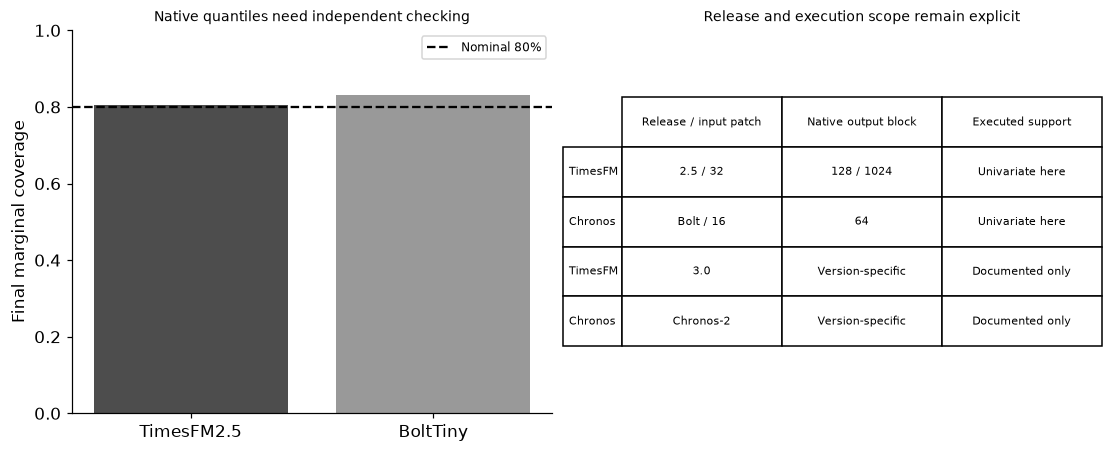

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));xx=np.arange(2);axes[0].bar(xx,[r['middle80_coverage'] for r in bands],color=['.3','.6']);axes[0].axhline(.8,linestyle='--',color='black',label='Nominal 80%');axes[0].set(xticks=xx,xticklabels=['TimesFM2.5','BoltTiny'],ylim=(0,1),ylabel='Final marginal coverage',title='Native quantiles need independent checking');axes[0].legend(fontsize=8)
table=[['2.5 / 32','128 / 1024','Univariate here'],['Bolt / 16','64','Univariate here'],['3.0','Version-specific','Documented only'],['Chronos-2','Version-specific','Documented only']];axes[1].axis('off');axes[1].table(cellText=table,rowLabels=['TimesFM','Chronos','TimesFM','Chronos'],colLabels=['Release / input patch','Native output block','Executed support'],loc='center',cellLoc='center').auto_set_font_size(False)
for cell in axes[1].tables[0].get_celld().values():cell.set_fontsize(7);cell.set_height(.13)
axes[1].set_title('Release and execution scope remain explicit');plt.show()
assert all(np.isfinite(r['MAE']) for r in rows) and all(r['mean_width']>=0 for r in bands)


In [4]:
summary={'example_id':'code_151','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual pinned TimesFM2.5 and ChronosBoltTiny CPU inference', 'explicit model/config byte hashes and offline loading', 'multiple origins kept within independent generated series', 'seasonal local autoregression and lagged-tree controls', 'native quantile shape coverage and immutable checkpoint parameters'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual pinned TimesFM2.5 and ChronosBoltTiny CPU inference", "explicit model/config byte hashes and offline loading", "multiple origins kept within independent generated series", "seasonal local autoregression and lagged-tree controls", "native quantile shape coverage and immutable checkpoint parameters"], "elapsed_seconds": 5.065, "example_id": "code_151", "hardware": "Darwin arm64 CPU", "results": {"Bolt_input_patch": 16, "Bolt_parameters": 8652672, "TimesFM_input_patch": 32, "TimesFM_total_parameters": 231289280, "comparisons": [{"MAE": 0.1893700369530254, "independent_series": 32, "median_series_MAE": 0.18833212057749432, "model": "Seasonal repeat", "origins_per_series": 3}, {"MAE": 0.1548809636636671, "independent_series": 32, "median_series_MAE": 0.15700418841369845, "model": "Local ridge AR", "origins_per_series": 3}, {"MAE": 0.19670160574447298, "independent_series": 32, "median_series_MAE": 0.1775961353375753, "model": "Lagged